In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split


In [4]:
data={
    "Study_Hours":[2.5,5.1,3.2,8.5,3.5,1.5,9.2,5.5,8.3,2.7,7.7,5.9,4.5,3.3,1.1,8.9,2.5,1.9,6.1,7.4],
    "Results":["Fail","Pass","Fail","Pass","Fail","Fail","Pass","Pass","Pass","Fail","Pass","Pass","Pass","Fail","Fail","Pass","Fail","Fail","Pass","Pass"]
}
df=pd.DataFrame(data)
df["Results_Encoded"]=df["Results"].map({"Fail":0,"Pass":1})
print(df.head())

   Study_Hours Results  Results_Encoded
0          2.5    Fail                0
1          5.1    Pass                1
2          3.2    Fail                0
3          8.5    Pass                1
4          3.5    Fail                0


In [5]:
x=df[["Study_Hours"]]
y=df["Results_Encoded"]
X_train, X_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)
model=LogisticRegression()
model.fit(X_train,y_train)
print("trained success")

trained success


In [6]:
y_pred=model.predict(X_test)
print("Actual test value: ",y_test.values)
print("Predicted values: ",y_pred)
test_probs=model.predict_proba(X_test)
print("Predicted probabilities: ",np.round(test_probs,4))
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy: ",accuracy)
cm=confusion_matrix(y_test,y_pred)
print("Confusion Matrix: \n",cm)
report=classification_report(y_test,y_pred,target_names=["Fail","Pass"])
print(report)



Actual test value:  [0 0 1 1]
Predicted values:  [0 0 1 1]
Predicted probabilities:  [[0.9351 0.0649]
 [0.9722 0.0278]
 [0.0011 0.9989]
 [0.2376 0.7624]]
Accuracy:  1.0
Confusion Matrix: 
 [[2 0]
 [0 2]]
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         2
        Pass       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



In [8]:
new_students=pd.DataFrame({"Study_Hours":[4.5,6.7,2.1,8.0]})
new_predictions=model.predict(new_students)
new_probabilities=model.predict_proba(new_students)
print("predicted values for new students: ",new_predictions)
print("predicted probabilities for new students: ",np.round(new_probabilities,4))


predicted values for new students:  [1 1 0 1]
predicted probabilities for new students:  [[0.4302 0.5698]
 [0.0286 0.9714]
 [0.963  0.037 ]
 [0.0043 0.9957]]


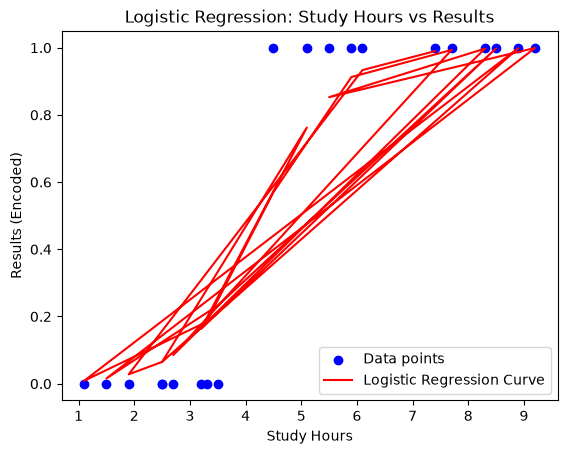

In [9]:
plt.Figure(figsize=(8,6))
plt.scatter(df["Study_Hours"],df["Results_Encoded"],color="blue",label="Data points")
plt.xlabel("Study Hours")
plt.ylabel("Results (Encoded)")
plt.title("Logistic Regression: Study Hours vs Results")
plt.plot(df["Study_Hours"],model.predict_proba(df[["Study_Hours"]])[:,1],color="red",label="Logistic Regression Curve")
plt.legend()
